<a href="https://colab.research.google.com/github/kkuttimani/ML/blob/ML-Random-Forest-%26-XGBoost-on-Attrition/Attrition_Prediction_Random_Forest_%26_XGBoost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"kuttimanik","key":"3a95f75a71a201245e309f208b410aac"}'}

In [3]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [4]:
!kaggle datasets download -d stealthtechnologies/employee-attrition-dataset
!unzip -o employee-attrition-dataset.zip -d attrition_data
!ls attrition_data

Dataset URL: https://www.kaggle.com/datasets/stealthtechnologies/employee-attrition-dataset
License(s): apache-2.0
100% 1.72M/1.72M [00:00<00:00, 135MB/s]

Archive:  employee-attrition-dataset.zip
  inflating: attrition_data/test.csv  
  inflating: attrition_data/train.csv  
test.csv  train.csv


In [5]:
import pandas as pd

train = pd.read_csv("attrition_data/train.csv")
test = pd.read_csv("attrition_data/test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)
train.head()

Train shape: (59598, 24)
Test shape: (14900, 24)


,Employee ID,Age,Gender,Years at Company,Job Role,Monthly Income,Work-Life Balance,Job Satisfaction,Performance Rating,Number of Promotions,...,Number of Dependents,Job Level,Company Size,Company Tenure,Remote Work,Leadership Opportunities,Innovation Opportunities,Company Reputation,Employee Recognition,Attrition
0,8410,31,Male,19,Education,5390,Excellent,Medium,Average,2,...,0,Mid,Medium,89,No,No,No,Excellent,Medium,Stayed
1,64756,59,Female,4,Media,5534,Poor,High,Low,3,...,3,Mid,Medium,21,No,No,No,Fair,Low,Stayed
2,30257,24,Female,10,Healthcare,8159,Good,High,Low,0,...,3,Mid,Medium,74,No,No,No,Poor,Low,Stayed
3,65791,36,Female,7,Education,3989,Good,High,High,1,...,2,Mid,Small,50,Yes,No,No,Good,Medium,Stayed
4,65026,56,Male,41,Education,4821,Fair,Very High,Average,0,...,0,Senior,Medium,68,No,No,No,Fair,Medium,Stayed


In [6]:
train.info()
print(train["Attrition"].value_counts(normalize=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59598 entries, 0 to 59597
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Employee ID               59598 non-null  int64 
 1   Age                       59598 non-null  int64 
 2   Gender                    59598 non-null  object
 3   Years at Company          59598 non-null  int64 
 4   Job Role                  59598 non-null  object
 5   Monthly Income            59598 non-null  int64 
 6   Work-Life Balance         59598 non-null  object
 7   Job Satisfaction          59598 non-null  object
 8   Performance Rating        59598 non-null  object
 9   Number of Promotions      59598 non-null  int64 
 10  Overtime                  59598 non-null  object
 11  Distance from Home        59598 non-null  int64 
 12  Education Level           59598 non-null  object
 13  Marital Status            59598 non-null  object
 14  Number of Dependents  

In [7]:
# Duplicates and the category values in each text column
print("Duplicate rows:", train.duplicated().sum())
print("Duplicate Employee IDs:", train["Employee ID"].duplicated().sum())

for col in train.select_dtypes(include="object").columns:
    print(f"\n{col}: {train[col].unique().tolist()}")

Duplicate rows: 0
Duplicate Employee IDs: 0

Gender: ['Male', 'Female']

Job Role: ['Education', 'Media', 'Healthcare', 'Technology', 'Finance']

Work-Life Balance: ['Excellent', 'Poor', 'Good', 'Fair']

Job Satisfaction: ['Medium', 'High', 'Very High', 'Low']

Performance Rating: ['Average', 'Low', 'High', 'Below Average']

Overtime: ['No', 'Yes']

Education Level: ['Associate Degree', 'Master’s Degree', 'Bachelor’s Degree', 'High School', 'PhD']

Marital Status: ['Married', 'Divorced', 'Single']

Job Level: ['Mid', 'Senior', 'Entry']

Company Size: ['Medium', 'Small', 'Large']

Remote Work: ['No', 'Yes']

Leadership Opportunities: ['No', 'Yes']

Innovation Opportunities: ['No', 'Yes']

Company Reputation: ['Excellent', 'Fair', 'Poor', 'Good']

Employee Recognition: ['Medium', 'Low', 'High', 'Very High']

Attrition: ['Stayed', 'Left']


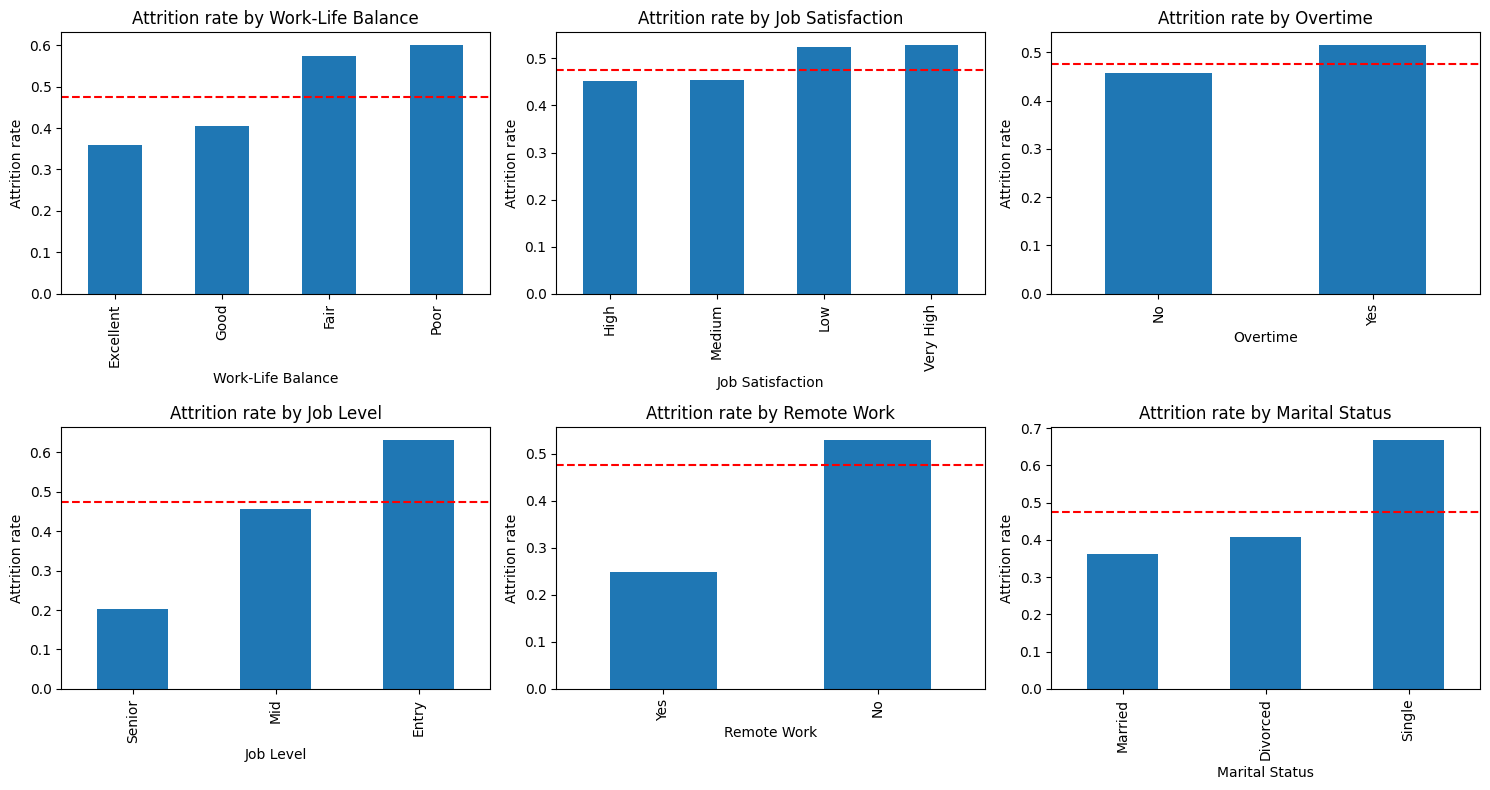

In [8]:
import matplotlib.pyplot as plt

# Target as 1/0 so we can average it (mean = attrition rate)
train["Left"] = (train["Attrition"] == "Left").astype(int)

cat_cols = ["Work-Life Balance", "Job Satisfaction", "Overtime",
            "Job Level", "Remote Work", "Marital Status"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cat_cols):
    train.groupby(col)["Left"].mean().sort_values().plot(kind="bar", ax=ax)
    ax.set_title(f"Attrition rate by {col}")
    ax.set_ylabel("Attrition rate")
    ax.axhline(train["Left"].mean(), color="red", linestyle="--")  # overall rate
plt.tight_layout()
plt.show()

In [9]:
num_cols = ["Age", "Years at Company", "Monthly Income",
            "Number of Promotions", "Distance from Home", "Company Tenure"]

print(train.groupby("Attrition")[num_cols].mean().round(1))

            Age  Years at Company  Monthly Income  Number of Promotions  \
Attrition                                                                 
Left       37.9              15.0          7276.7                   0.7   
Stayed     39.1              16.4          7325.7                   0.9   

           Distance from Home  Company Tenure  
Attrition                                      
Left                     52.9            55.0  
Stayed                   47.4            56.5  


In [10]:
import pandas as pd

def prepare(df):
    df = df.copy()
    df = df.drop(columns=["Employee ID"])

    # Target
    df["Attrition"] = (df["Attrition"] == "Left").astype(int)

    # Ordinal columns
    ordinal_maps = {
        "Work-Life Balance":   {"Poor": 0, "Fair": 1, "Good": 2, "Excellent": 3},
        "Job Satisfaction":    {"Low": 0, "Medium": 1, "High": 2, "Very High": 3},
        "Performance Rating":  {"Low": 0, "Below Average": 1, "Average": 2, "High": 3},
        "Education Level":     {"High School": 0, "Associate Degree": 1, "Bachelor’s Degree": 2,
                                "Master’s Degree": 3, "PhD": 4},
        "Job Level":           {"Entry": 0, "Mid": 1, "Senior": 2},
        "Company Size":        {"Small": 0, "Medium": 1, "Large": 2},
        "Company Reputation":  {"Poor": 0, "Fair": 1, "Good": 2, "Excellent": 3},
        "Employee Recognition":{"Low": 0, "Medium": 1, "High": 2, "Very High": 3},
    }
    for col, mapping in ordinal_maps.items():
        df[col] = df[col].map(mapping)

    # Binary Yes/No columns
    for col in ["Overtime", "Remote Work", "Leadership Opportunities", "Innovation Opportunities"]:
        df[col] = (df[col] == "Yes").astype(int)

    df["Gender"] = (df["Gender"] == "Male").astype(int)

    # Nominal columns: one-hot
    df = pd.get_dummies(df, columns=["Job Role", "Marital Status"], drop_first=True)
    return df

train_prep = prepare(train.drop(columns=["Left"]))
test_prep = prepare(test)

# Safety check: any unmapped category becomes NaN
print("Missing values after encoding:\n", train_prep.isna().sum()[train_prep.isna().sum() > 0])
print("Shape:", train_prep.shape, test_prep.shape)

Missing values after encoding:
 Series([], dtype: int64)
Shape: (59598, 27) (14900, 27)


In [11]:
X_train = train_prep.drop(columns="Attrition")
y_train = train_prep["Attrition"]
X_test = test_prep.drop(columns="Attrition")
y_test = test_prep["Attrition"]

# Make sure both have identical columns in the same order
X_test = X_test[X_train.columns]
print(X_train.shape, X_test.shape)

(59598, 26) (14900, 26)


In [12]:
import time
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)
from xgboost import XGBClassifier   # preinstalled in Colab

In [13]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    n_jobs=-1,          # use all CPU cores
    random_state=42
)

start = time.time()
rf.fit(X_train, y_train)
print(f"Training time: {time.time() - start:.1f}s")

rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]

Training time: 30.6s


In [14]:
xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    n_jobs=-1,
    random_state=42
)

start = time.time()
xgb.fit(X_train, y_train)
print(f"Training time: {time.time() - start:.1f}s")

xgb_pred = xgb.predict(X_test)
xgb_proba = xgb.predict_proba(X_test)[:, 1]

Training time: 2.4s


In [15]:
def evaluate(name, y_true, pred, proba):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, proba),
    }

results = pd.DataFrame([
    evaluate("Random Forest", y_test, rf_pred, rf_proba),
    evaluate("XGBoost", y_test, xgb_pred, xgb_proba),
]).round(4)
results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.7539,0.7418,0.7339,0.7379,0.8433
1,XGBoost,0.7554,0.7395,0.7436,0.7415,0.8475


In [16]:
print("Random Forest confusion matrix:\n", confusion_matrix(y_test, rf_pred))
print("\nXGBoost confusion matrix:\n", confusion_matrix(y_test, xgb_pred))

Random Forest confusion matrix:
 [[6072 1796]
 [1871 5161]]

XGBoost confusion matrix:
 [[6026 1842]
 [1803 5229]]


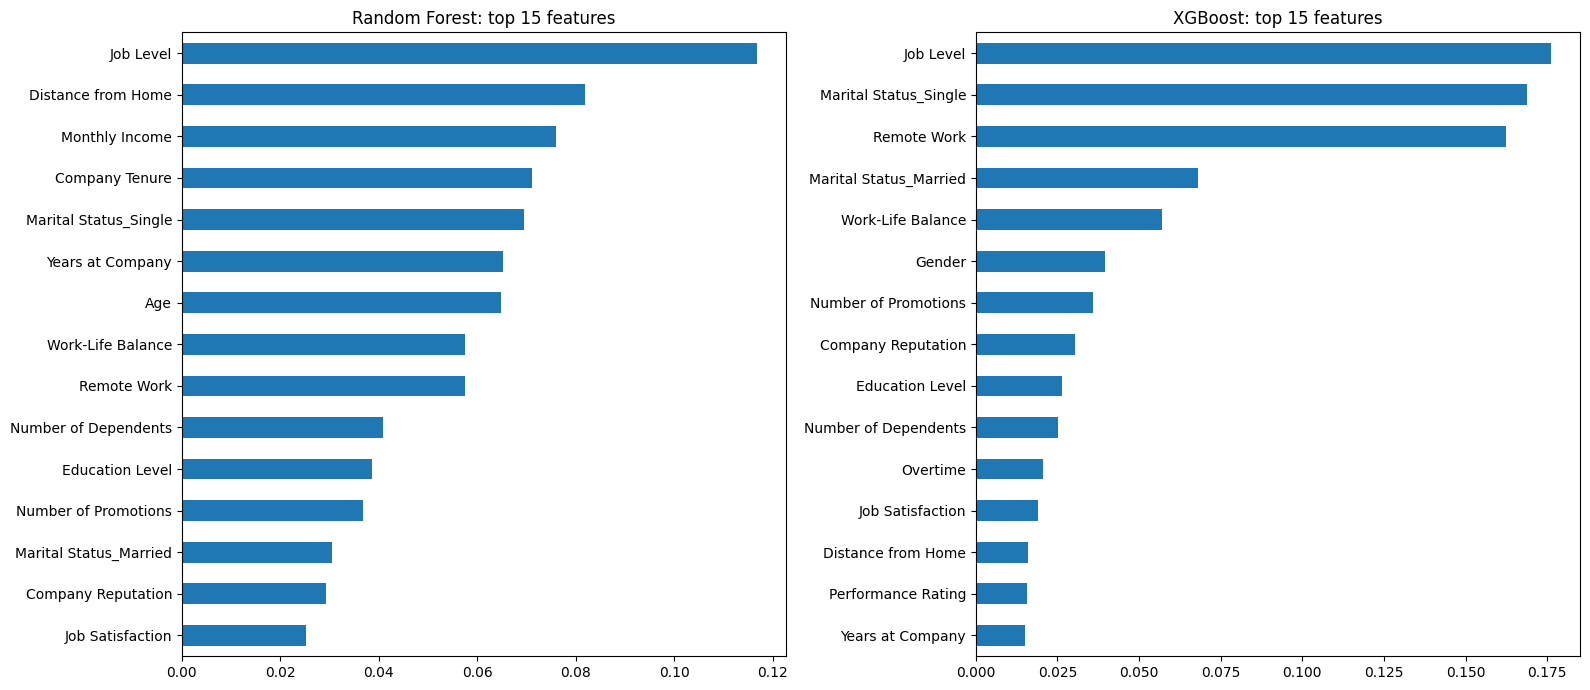

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, model, title in zip(axes, [rf, xgb], ["Random Forest", "XGBoost"]):
    imp = pd.Series(model.feature_importances_, index=X_train.columns).sort_values()
    imp.tail(15).plot(kind="barh", ax=ax)
    ax.set_title(f"{title}: top 15 features")

plt.tight_layout()
plt.show()